In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE_DIR = '/content/drive/MyDrive/NewCattleSense/model1_artifacts'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"All files will be saved to: {SAVE_DIR}")
print("This path survives runtime restarts — always save here, never to /content/ alone.")

Mounted at /content/drive
All files will be saved to: /content/drive/MyDrive/NewCattleSense/model1_artifacts
This path survives runtime restarts — always save here, never to /content/ alone.


In [ ]:
def find_dataset_root(base_path='/content/drive/MyDrive', target_folders=('mastitis', 'normal')):
    candidates = []
    for root, dirs, files in os.walk(base_path):
        lower_dirs = [d.lower() for d in dirs]
        if 'mastitis' in lower_dirs and 'normal' in lower_dirs:
            candidates.append(root)
    return candidates

found = find_dataset_root()
DATASET_ROOT = found[0]
mastitis_dir = os.path.join(DATASET_ROOT, 'mastitis')
normal_dir = os.path.join(DATASET_ROOT, 'normal')
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')

mastitis_count = sum(1 for f in os.listdir(mastitis_dir) if f.lower().endswith(valid_ext))
normal_count = sum(1 for f in os.listdir(normal_dir) if f.lower().endswith(valid_ext))

print(f"Dataset root: {DATASET_ROOT}")
print(f"Mastitis: {mastitis_count} | Normal: {normal_count} | Total: {mastitis_count + normal_count}")

Dataset root: /content/drive/MyDrive/NewCattleSense/dataset/images
Mastitis: 736 | Normal: 436 | Total: 1172


In [ ]:
import hashlib
from collections import defaultdict

!pip install imagehash --quiet
import imagehash
from PIL import Image as PILImage

def compute_hash(filepath):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            hasher.update(chunk)
    return hasher.hexdigest()

def find_exact_duplicates(folder):
    hash_map = defaultdict(list)
    for fname in sorted(os.listdir(folder)):
        fpath = os.path.join(folder, fname)
        if fname.lower().endswith(valid_ext):
            hash_map[compute_hash(fpath)].append(fname)
    return hash_map

def compute_phash(filepath):
    with PILImage.open(filepath) as img:
        return imagehash.phash(img)

def find_near_duplicates(folder, threshold=5):
    files = [f for f in sorted(os.listdir(folder)) if f.lower().endswith(valid_ext)]
    hashes = {}
    for fname in files:
        try:
            hashes[fname] = compute_phash(os.path.join(folder, fname))
        except Exception:
            pass
    pairs = []
    fnames = list(hashes.keys())
    for i in range(len(fnames)):
        for j in range(i + 1, len(fnames)):
            dist = hashes[fnames[i]] - hashes[fnames[j]]
            if dist <= threshold:
                pairs.append((fnames[i], fnames[j], dist))
    return pairs

print("Hashing mastitis...")
mastitis_hashes = find_exact_duplicates(mastitis_dir)
print("Hashing normal...")
normal_hashes = find_exact_duplicates(normal_dir)
print("Near-dup mastitis...")
mastitis_near_dupes = find_near_duplicates(mastitis_dir)
print("Near-dup normal...")
normal_near_dupes = find_near_duplicates(normal_dir)

# Union-Find clustering
class UnionFind:
    def __init__(self):
        self.parent = {}
    def find(self, x):
        self.parent.setdefault(x, x)
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx != ry:
            self.parent[rx] = ry

uf = UnionFind()
for fname in os.listdir(mastitis_dir):
    if fname.lower().endswith(valid_ext):
        uf.find(('mastitis', fname))
for fname in os.listdir(normal_dir):
    if fname.lower().endswith(valid_ext):
        uf.find(('normal', fname))

for h, files in mastitis_hashes.items():
    for f in files[1:]:
        uf.union(('mastitis', files[0]), ('mastitis', f))
for h, files in normal_hashes.items():
    for f in files[1:]:
        uf.union(('normal', files[0]), ('normal', f))
for f1, f2, dist in mastitis_near_dupes:
    uf.union(('mastitis', f1), ('mastitis', f2))
for f1, f2, dist in normal_near_dupes:
    uf.union(('normal', f1), ('normal', f2))

clusters = defaultdict(list)
for key in uf.parent:
    clusters[uf.find(key)].append(key)

file_to_cluster = {}
for cid, members in clusters.items():
    for m in members:
        file_to_cluster[m] = cid

print(f"\nTotal images: {len(uf.parent)} | Total clusters: {len(clusters)}")

import pickle
with open(os.path.join(SAVE_DIR, 'image_clusters.pkl'), 'wb') as f:
    pickle.dump(dict(clusters), f)
print(f"Clusters saved to {SAVE_DIR}/image_clusters.pkl")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.0 MB/s eta 0:00:00
Hashing mastitis...
Hashing normal...
Near-dup mastitis...
Near-dup normal...

Total images: 1172 | Total clusters: 940
Clusters saved to /content/drive/MyDrive/NewCattleSense/model1_artifacts/image_clusters.pkl


In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

all_files = []
for fname in os.listdir(mastitis_dir):
    if fname.lower().endswith(valid_ext):
        all_files.append({'filepath': os.path.join(mastitis_dir, fname), 'filename': fname,
                           'label': 'mastitis', 'label_int': 1,
                           'cluster_id': str(file_to_cluster[('mastitis', fname)])})
for fname in os.listdir(normal_dir):
    if fname.lower().endswith(valid_ext):
        all_files.append({'filepath': os.path.join(normal_dir, fname), 'filename': fname,
                           'label': 'normal', 'label_int': 0,
                           'cluster_id': str(file_to_cluster[('normal', fname)])})

df = pd.DataFrame(all_files)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(gss1.split(df, groups=df['cluster_id']))
df_trainval = df.iloc[trainval_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=42)
train_idx, val_idx = next(gss2.split(df_trainval, groups=df_trainval['cluster_id']))
df_train = df_trainval.iloc[train_idx].reset_index(drop=True)
df_val = df_trainval.iloc[val_idx].reset_index(drop=True)

df_train['split'] = 'train'
df_val['split'] = 'val'
df_test['split'] = 'test'
df_all_splits = pd.concat([df_train, df_val, df_test], ignore_index=True)

# Save directly to Drive this time
df_all_splits.to_csv(os.path.join(SAVE_DIR, 'dataset_splits.csv'), index=False)
print(f"Split sizes — Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"Saved to {SAVE_DIR}/dataset_splits.csv")

df_train_split = df_train
df_val_split = df_val
df_test_split = df_test

Split sizes — Train: 814, Val: 181, Test: 177
Saved to /content/drive/MyDrive/NewCattleSense/model1_artifacts/dataset_splits.csv


In [ ]:
import tensorflow as tf
import numpy as np

BATCH_SIZE = 32
TARGET_SIZE = (224, 224)
JPEG_QUALITY = 85

def tf_preprocess(filepath, label):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, TARGET_SIZE, method='bilinear')
    img = tf.cast(img, tf.uint8)
    encoded = tf.image.encode_jpeg(img, quality=JPEG_QUALITY)
    img = tf.image.decode_jpeg(encoded, channels=3)
    return tf.cast(img, tf.float32), label

def tf_augment(img, label):
    img = img / 255.0
    img = tf.image.random_flip_left_right(img)
    crop_frac = tf.random.uniform([], 0.85, 1.0)
    crop_size = tf.cast(crop_frac * 224, tf.int32)
    img = tf.image.random_crop(img, size=[crop_size, crop_size, 3])
    img = tf.image.resize(img, TARGET_SIZE)
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    img = tf.image.random_saturation(img, lower=0.7, upper=1.3)
    img = tf.image.random_hue(img, max_delta=0.05)
    img = tf.clip_by_value(img, 0.0, 1.0)
    img_uint8 = tf.cast(img * 255.0, tf.uint8)
    img_uint8 = tf.image.random_jpeg_quality(img_uint8, min_jpeg_quality=60, max_jpeg_quality=95)  # FIXED
    img = tf.cast(img_uint8, tf.float32) / 255.0
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img * 255.0, label

def build_dataset(df_subset, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    filepaths = df_subset['filepath'].values
    labels = df_subset['label_int'].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(filepaths), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(tf_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(tf_augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(df_train_split, shuffle=True, augment=True)
val_ds = build_dataset(df_val_split, shuffle=False, augment=False)
test_ds = build_dataset(df_test_split, shuffle=False, augment=False)

print(f"Train batches: {tf.data.experimental.cardinality(train_ds).numpy()}")
print(f"Val batches:   {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"Test batches:  {tf.data.experimental.cardinality(test_ds).numpy()}")

Train batches: 26
Val batches:   6
Test batches:  6


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50, EfficientNetB0, MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight

def build_model(backbone_name, input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)
    if backbone_name == 'resnet50':
        x = tf.keras.applications.resnet50.preprocess_input(inputs)
        base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=x)
    elif backbone_name == 'efficientnetb0':
        x = tf.keras.applications.efficientnet.preprocess_input(inputs)
        base_model = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=x)
    elif backbone_name == 'mobilenetv2':
        x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs=inputs, outputs=outputs, name=f'{backbone_name}_mastitis')
    return model

train_labels = df_train_split['label_int'].values
class_weights_arr = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weight_dict = {0: class_weights_arr[0], 1: class_weights_arr[1]}
print(f"Class weights: {class_weight_dict}")

def compile_and_train_stage1(model, model_name, train_ds, val_ds, epochs=15):
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall')])
    callbacks = [
        EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
        ModelCheckpoint(os.path.join(SAVE_DIR, f'{model_name}_stage1_best.keras'),
                         monitor='val_auc', mode='max', save_best_only=True)  # SAVES TO DRIVE
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                      class_weight=class_weight_dict, callbacks=callbacks, verbose=1)

Class weights: {0: np.float64(1.2839116719242902), 1: np.float64(0.8189134808853119)}


In [ ]:
print("=== Training ResNet50 (Stage 1: frozen backbone) ===")
resnet_model = build_model('resnet50')
resnet_history = compile_and_train_stage1(resnet_model, 'resnet50', train_ds, val_ds)
print("\n✓ Checkpoint auto-saved to Drive at each improved epoch.")

=== Training ResNet50 (Stage 1: frozen backbone) ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 37s 848ms/step - accuracy: 0.7150 - auc: 0.7738 - loss: 0.6314 - precision: 0.8046 - recall: 0.7042 - val_accuracy: 0.8177 - val_auc: 0.8999 - val_loss: 0.3845 - val_precision: 0.8909 - val_recall: 0.8235 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 270ms/step - accuracy: 0.7961 - auc: 0.8846 - loss: 0.4154 - precision: 0.8736 - recall: 0.7787 - val_accuracy: 0.7901 - val_auc: 0.9004 - val_loss: 0.4002 - val_precision: 0.9263 - val_recall: 0.7395 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 12s 326ms/step - accuracy: 0.8403 - auc: 0.9182 - loss: 0.3566 - precision: 0.9338 - recall: 0.7948 - val_accuracy: 0.8232 - val_auc: 0.9110 - val_loss: 0.3676 - val_precision: 0.9065 - val_recall: 0.8151 - learning_rate: 0.0010
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 319ms/step - accuracy: 0.8563 - auc: 0.9317 - loss: 0.3

In [ ]:
final_model = tf.keras.models.load_model(os.path.join(SAVE_DIR, 'resnet50_stage1_best.keras'))
final_model.save(os.path.join(SAVE_DIR, 'mastitis_image_model.keras'))

import json

class_names = {"0": "normal", "1": "mastitis"}
with open(os.path.join(SAVE_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f, indent=2)

preprocessing_config = {"target_size": [224, 224], "jpeg_quality": 85,
                         "preprocess_function": "resnet50 preprocess_input, applied internally"}
with open(os.path.join(SAVE_DIR, 'preprocessing_config.json'), 'w') as f:
    json.dump(preprocessing_config, f, indent=2)

threshold_config = {"selected_threshold": 0.25,
                     "selection_criterion": "best F1-score, prioritizing recall for clinical screening"}
with open(os.path.join(SAVE_DIR, 'threshold.json'), 'w') as f:
    json.dump(threshold_config, f, indent=2)

print(f"✓ All artifacts saved permanently to: {SAVE_DIR}")
print(os.listdir(SAVE_DIR))

✓ All artifacts saved permanently to: /content/drive/MyDrive/NewCattleSense/model1_artifacts
['image_clusters.pkl', 'dataset_splits.csv', 'resnet50_stage1_best.keras', 'mastitis_image_model.keras', 'class_names.json', 'preprocessing_config.json', 'threshold.json']


In [ ]:
best_epoch = np.argmax(resnet_history.history['val_auc']) + 1
print(f"Best epoch: {best_epoch}")
print(f"Best val_auc: {max(resnet_history.history['val_auc']):.4f}")
print(f"Val accuracy at that epoch: {resnet_history.history['val_accuracy'][best_epoch-1]:.4f}")

Best epoch: 7
Best val_auc: 0.9148
Val accuracy at that epoch: 0.8232


In [ ]:
final_model = tf.keras.models.load_model(os.path.join(SAVE_DIR, 'resnet50_stage1_best.keras'))
final_model.save(os.path.join(SAVE_DIR, 'mastitis_image_model.keras'))

import json

class_names = {"0": "normal", "1": "mastitis"}
with open(os.path.join(SAVE_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f, indent=2)

preprocessing_config = {"target_size": [224, 224], "jpeg_quality": 85,
                         "preprocess_function": "resnet50 preprocess_input, applied internally"}
with open(os.path.join(SAVE_DIR, 'preprocessing_config.json'), 'w') as f:
    json.dump(preprocessing_config, f, indent=2)

threshold_config = {"selected_threshold": 0.25,
                     "selection_criterion": "best F1-score, prioritizing recall for clinical screening"}
with open(os.path.join(SAVE_DIR, 'threshold.json'), 'w') as f:
    json.dump(threshold_config, f, indent=2)

metrics_summary = {
    "model_architecture": "ResNet50 (frozen backbone, Stage 1 transfer learning)",
    "val_auc": 0.9148,
    "val_accuracy_at_best_epoch": 0.8232,
    "best_epoch": 7,
    "note": "Re-trained after accidental runtime loss; minor run-to-run variance from original (val_auc 0.9282) due to weight init / augmentation stochasticity — both runs > 0.91 AUC"
}
with open(os.path.join(SAVE_DIR, 'metrics.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=2)

print(f"✓ All artifacts saved permanently to: {SAVE_DIR}")
for f in os.listdir(SAVE_DIR):
    size = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1024
    print(f"  {f}: {size:.1f} KB")

✓ All artifacts saved permanently to: /content/drive/MyDrive/NewCattleSense/model1_artifacts
  image_clusters.pkl: 73.1 KB
  dataset_splits.csv: 285.0 KB
  resnet50_stage1_best.keras: 95860.8 KB
  mastitis_image_model.keras: 95854.4 KB
  class_names.json: 0.0 KB
  preprocessing_config.json: 0.1 KB
  threshold.json: 0.1 KB
  metrics.json: 0.3 KB


In [ ]:
from skimage.feature import hog
from skimage.color import rgb2gray
import numpy as np
from PIL import Image as PILImage

def extract_classical_features(filepath, target_size=(224, 224)):
    """
    Extracts HOG (shape/edge) + color histogram (color distribution) features.
    Same harmonized preprocessing as the CNN pipeline for fair comparison.
    """
    with PILImage.open(filepath) as img:
        img = img.convert('RGB').resize(target_size, PILImage.BILINEAR)
        arr = np.array(img)

    # HOG features (on grayscale)
    gray = rgb2gray(arr)
    hog_features = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                        cells_per_block=(2, 2), feature_vector=True)

    # Color histogram features (per channel, coarse bins to keep dimensionality reasonable)
    hist_features = []
    for channel in range(3):
        hist, _ = np.histogram(arr[:, :, channel], bins=32, range=(0, 256))
        hist_features.extend(hist / hist.sum())  # normalize

    return np.concatenate([hog_features, np.array(hist_features)])

print("Extracting classical features for train/val/test (this will take a few minutes)...")

def build_feature_set(df_subset, desc):
    X, y = [], []
    for i, row in df_subset.iterrows():
        feat = extract_classical_features(row['filepath'])
        X.append(feat)
        y.append(row['label_int'])
        if (i+1) % 200 == 0:
            print(f"  {desc}: {i+1}/{len(df_subset)} processed")
    return np.array(X), np.array(y)

X_train_classical, y_train_classical = build_feature_set(df_train_split, "train")
X_val_classical, y_val_classical = build_feature_set(df_val_split, "val")
X_test_classical, y_test_classical = build_feature_set(df_test_split, "test")

print(f"\nFeature vector dimensionality: {X_train_classical.shape[1]}")
print(f"Train: {X_train_classical.shape}, Val: {X_val_classical.shape}, Test: {X_test_classical.shape}")

# Save for reuse
np.savez(os.path.join(SAVE_DIR, 'classical_features.npz'),
         X_train=X_train_classical, y_train=y_train_classical,
         X_val=X_val_classical, y_val=y_val_classical,
         X_test=X_test_classical, y_test=y_test_classical)
print("Saved to classical_features.npz")

Extracting classical features for train/val/test (this will take a few minutes)...
  train: 200/814 processed
  train: 400/814 processed
  train: 600/814 processed
  train: 800/814 processed

Feature vector dimensionality: 6180
Train: (814, 6180), Val: (181, 6180), Test: (177, 6180)
Saved to classical_features.npz


In [ ]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_classical)
X_test_scaled = scaler.transform(X_test_classical)

results_classical = []

def evaluate_model(model, X_test, y_test, model_name, feature_type, proba_fn=None):
    y_pred = model.predict(X_test)
    is_float_pred = np.issubdtype(y_pred.dtype, np.floating)
    y_pred_binary = (y_pred >= 0.5).astype(int) if is_float_pred else y_pred

    if proba_fn:
        y_proba = proba_fn(X_test)
    else:
        y_proba = y_pred

    acc = accuracy_score(y_test, y_pred_binary)
    try:
        auc = roc_auc_score(y_test, y_proba)
    except Exception:
        auc = None
    prec = precision_score(y_test, y_pred_binary, zero_division=0)
    rec = recall_score(y_test, y_pred_binary, zero_division=0)
    f1 = f1_score(y_test, y_pred_binary, zero_division=0)

    print(f"{model_name} ({feature_type}): acc={acc:.4f}, precision={prec:.4f}, recall={rec:.4f}, f1={f1:.4f}, auc={auc}")
    results_classical.append({
        'model': model_name, 'feature_type': feature_type, 'accuracy': acc,
        'precision': prec, 'recall': rec, 'f1': f1, 'auc': auc
    })

print("=== Linear Regression (baseline, not a real classifier) ===")
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train_classical)
evaluate_model(lin_reg, X_test_scaled, y_test_classical, 'Linear Regression', 'Classical (HOG+Color)')

print("\n=== Logistic Regression ===")
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_scaled, y_train_classical)
evaluate_model(log_reg, X_test_scaled, y_test_classical, 'Logistic Regression', 'Classical (HOG+Color)',
               proba_fn=lambda X: log_reg.predict_proba(X)[:, 1])

print("\n=== Decision Tree ===")
dt = DecisionTreeClassifier(max_depth=10, min_samples_split=10, min_samples_leaf=5,
                             class_weight='balanced', random_state=42)
dt.fit(X_train_scaled, y_train_classical)
evaluate_model(dt, X_test_scaled, y_test_classical, 'Decision Tree', 'Classical (HOG+Color)',
               proba_fn=lambda X: dt.predict_proba(X)[:, 1])

print("\n=== Random Forest ===")
rf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=5,
                             min_samples_leaf=2, class_weight='balanced', random_state=42)
rf.fit(X_train_scaled, y_train_classical)
evaluate_model(rf, X_test_scaled, y_test_classical, 'Random Forest', 'Classical (HOG+Color)',
               proba_fn=lambda X: rf.predict_proba(X)[:, 1])

print("\n=== SVM (RBF) ===")
svm = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, class_weight='balanced', random_state=42)
svm.fit(X_train_scaled, y_train_classical)
evaluate_model(svm, X_test_scaled, y_test_classical, 'SVM (RBF)', 'Classical (HOG+Color)',
               proba_fn=lambda X: svm.predict_proba(X)[:, 1])

df_results_classical = pd.DataFrame(results_classical)
df_results_classical.to_csv(os.path.join(SAVE_DIR, 'classical_ml_results.csv'), index=False)
print("\nSaved to classical_ml_results.csv")

=== Linear Regression (baseline, not a real classifier) ===
Linear Regression (Classical (HOG+Color)): acc=0.6836, precision=0.8137, recall=0.6917, f1=0.7477, auc=0.7336257309941521

=== Logistic Regression ===
Logistic Regression (Classical (HOG+Color)): acc=0.6780, precision=0.8119, recall=0.6833, f1=0.7421, auc=0.7478070175438597

=== Decision Tree ===
Decision Tree (Classical (HOG+Color)): acc=0.5367, precision=0.7317, recall=0.5000, f1=0.5941, auc=0.5114766081871345

=== Random Forest ===
Random Forest (Classical (HOG+Color)): acc=0.7458, precision=0.8000, recall=0.8333, f1=0.8163, auc=0.7676900584795322

=== SVM (RBF) ===
SVM (RBF) (Classical (HOG+Color)): acc=0.7401, precision=0.8558, recall=0.7417, f1=0.7946, auc=0.802046783625731

Saved to classical_ml_results.csv


In [ ]:
# Extract deep features from the frozen ResNet50 backbone (GAP output, before the classification head)
feature_extractor = tf.keras.models.Model(
    inputs=final_model.input,
    outputs=final_model.get_layer('global_average_pooling2d').output  # adjust name if needed
)

# Check the actual GAP layer name if the above fails
gap_layer_name = None
for layer in final_model.layers:
    if 'global_average_pooling' in layer.name:
        gap_layer_name = layer.name
        break
print(f"Using GAP layer: {gap_layer_name}")

feature_extractor = tf.keras.models.Model(
    inputs=final_model.input,
    outputs=final_model.get_layer(gap_layer_name).output
)

def extract_cnn_features(df_subset, desc):
    ds = build_dataset(df_subset, batch_size=32, shuffle=False, augment=False)
    features, labels = [], []
    for imgs, lbls in ds:
        feats = feature_extractor.predict(imgs, verbose=0)
        features.append(feats)
        labels.append(lbls.numpy())
    print(f"{desc}: extracted {sum(f.shape[0] for f in features)} feature vectors")
    return np.vstack(features), np.concatenate(labels)

print("Extracting CNN (ResNet50 GAP) features...")
X_train_cnn, y_train_cnn = extract_cnn_features(df_train_split, "train")
X_val_cnn, y_val_cnn = extract_cnn_features(df_val_split, "val")
X_test_cnn, y_test_cnn = extract_cnn_features(df_test_split, "test")

print(f"CNN feature dimensionality: {X_train_cnn.shape[1]}")

np.savez(os.path.join(SAVE_DIR, 'cnn_features.npz'),
         X_train=X_train_cnn, y_train=y_train_cnn,
         X_val=X_val_cnn, y_val=y_val_cnn,
         X_test=X_test_cnn, y_test=y_test_cnn)

# Train the same 4 classifiers on CNN features
scaler_cnn = StandardScaler()
X_train_cnn_scaled = scaler_cnn.fit_transform(X_train_cnn)
X_test_cnn_scaled = scaler_cnn.transform(X_test_cnn)

print("\n=== Logistic Regression (CNN Features) ===")
log_reg_cnn = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg_cnn.fit(X_train_cnn_scaled, y_train_cnn)
evaluate_model(log_reg_cnn, X_test_cnn_scaled, y_test_cnn, 'Logistic Regression', 'CNN Features',
               proba_fn=lambda X: log_reg_cnn.predict_proba(X)[:, 1])

print("\n=== Decision Tree (CNN Features) ===")
dt_cnn = DecisionTreeClassifier(max_depth=10, min_samples_split=10, min_samples_leaf=5,
                                  class_weight='balanced', random_state=42)
dt_cnn.fit(X_train_cnn_scaled, y_train_cnn)
evaluate_model(dt_cnn, X_test_cnn_scaled, y_test_cnn, 'Decision Tree', 'CNN Features',
               proba_fn=lambda X: dt_cnn.predict_proba(X)[:, 1])

print("\n=== Random Forest (CNN Features) ===")
rf_cnn = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=5,
                                  min_samples_leaf=2, class_weight='balanced', random_state=42)
rf_cnn.fit(X_train_cnn_scaled, y_train_cnn)
evaluate_model(rf_cnn, X_test_cnn_scaled, y_test_cnn, 'Random Forest', 'CNN Features',
               proba_fn=lambda X: rf_cnn.predict_proba(X)[:, 1])

print("\n=== SVM RBF (CNN Features) ===")
svm_cnn = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, class_weight='balanced', random_state=42)
svm_cnn.fit(X_train_cnn_scaled, y_train_cnn)
evaluate_model(svm_cnn, X_test_cnn_scaled, y_test_cnn, 'SVM (RBF)', 'CNN Features',
               proba_fn=lambda X: svm_cnn.predict_proba(X)[:, 1])

df_results_classical.to_csv(os.path.join(SAVE_DIR, 'classical_ml_results.csv'), index=False)
print(f"\nUpdated results saved. Total rows: {len(df_results_classical)}")

Using GAP layer: global_average_pooling2d
Extracting CNN (ResNet50 GAP) features...
train: extracted 814 feature vectors
val: extracted 181 feature vectors
test: extracted 177 feature vectors
CNN feature dimensionality: 2048

=== Logistic Regression (CNN Features) ===
Logistic Regression (CNN Features): acc=0.8418, precision=0.9182, recall=0.8417, f1=0.8783, auc=0.913888888888889

=== Decision Tree (CNN Features) ===
Decision Tree (CNN Features): acc=0.7514, precision=0.8519, recall=0.7667, f1=0.8070, auc=0.7326754385964912

=== Random Forest (CNN Features) ===
Random Forest (CNN Features): acc=0.8362, precision=0.8824, recall=0.8750, f1=0.8787, auc=0.9036549707602339

=== SVM RBF (CNN Features) ===
SVM (RBF) (CNN Features): acc=0.8418, precision=0.9035, recall=0.8583, f1=0.8803, auc=0.9353801169590643

Updated results saved. Total rows: 5


In [ ]:
try:
    print(f"final_model exists: {final_model}")
    print(f"df_test_split shape: {df_test_split.shape}")
    print("✓ Runtime still connected — no need to reload, skip Cell 1.")
except NameError:
    print("✗ Runtime was restarted — need to run Cell 1 (reload from Drive).")

✗ Runtime was restarted — need to run Cell 1 (reload from Drive).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import io
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

SAVE_DIR = '/content/drive/MyDrive/NewCattleSense/model1_artifacts'
print(f"Save directory: {SAVE_DIR}")
print(f"Files available: {os.listdir(SAVE_DIR)}")

# Reload dataset paths
DATASET_ROOT = '/content/drive/MyDrive/NewCattleSense/dataset/images'
mastitis_dir = os.path.join(DATASET_ROOT, 'mastitis')
normal_dir = os.path.join(DATASET_ROOT, 'normal')
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')

# Reload the saved split assignments (exact same split, no re-randomization)
df_splits = pd.read_csv(os.path.join(SAVE_DIR, 'dataset_splits.csv'))
df_train_split = df_splits[df_splits['split'] == 'train'].reset_index(drop=True)
df_val_split = df_splits[df_splits['split'] == 'val'].reset_index(drop=True)
df_test_split = df_splits[df_splits['split'] == 'test'].reset_index(drop=True)
print(f"\nReloaded splits — Train: {len(df_train_split)}, Val: {len(df_val_split)}, Test: {len(df_test_split)}")

# Rebuild class weights
train_labels = df_train_split['label_int'].values
class_weights_arr = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weight_dict = {0: class_weights_arr[0], 1: class_weights_arr[1]}
print(f"Class weights: {class_weight_dict}")

# Rebuild tf.data pipeline
BATCH_SIZE = 32
TARGET_SIZE = (224, 224)
JPEG_QUALITY = 85

def tf_preprocess(filepath, label):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, TARGET_SIZE, method='bilinear')
    img = tf.cast(img, tf.uint8)
    encoded = tf.image.encode_jpeg(img, quality=JPEG_QUALITY)
    img = tf.image.decode_jpeg(encoded, channels=3)
    return tf.cast(img, tf.float32), label

def build_dataset(df_subset, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    filepaths = df_subset['filepath'].values
    labels = df_subset['label_int'].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(filepaths), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(tf_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

test_ds = build_dataset(df_test_split, shuffle=False, augment=False)

# Reload the final trained model
final_model = tf.keras.models.load_model(os.path.join(SAVE_DIR, 'mastitis_image_model.keras'))
print(f"\n✓ Final model reloaded — {final_model.count_params():,} params")

# Sanity check
sample_path = df_test_split.iloc[0]['filepath']
sample_img = tf_preprocess(sample_path, 0)[0].numpy()
sample_proba = final_model.predict(np.expand_dims(sample_img, 0), verbose=0)[0][0]
print(f"Sanity check prediction: {sample_proba:.4f}")

Mounted at /content/drive
Save directory: /content/drive/MyDrive/NewCattleSense/model1_artifacts
Files available: ['image_clusters.pkl', 'dataset_splits.csv', 'resnet50_stage1_best.keras', 'metrics.json', 'preprocessing_config.json', 'threshold.json', 'class_names.json', 'mastitis_image_model.keras', 'classical_features.npz', 'cnn_features.npz', 'classical_ml_results.csv']

Reloaded splits — Train: 814, Val: 181, Test: 177
Class weights: {0: np.float64(1.2839116719242902), 1: np.float64(0.8189134808853119)}

✓ Final model reloaded — 23,850,113 params
Sanity check prediction: 0.9595


In [ ]:
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve, auc, ConfusionMatrixDisplay

y_true = []
y_pred_proba = []

for imgs, labels in test_ds:
    preds = final_model.predict(imgs, verbose=0)
    y_pred_proba.extend(preds.flatten())
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_proba = np.array(y_pred_proba)

FINAL_THRESHOLD = 0.25
y_pred = (y_pred_proba >= FINAL_THRESHOLD).astype(int)

print(f"Test set size: {len(y_true)}")
print(f"Predictions at threshold={FINAL_THRESHOLD} computed")

Test set size: 177
Predictions at threshold=0.25 computed


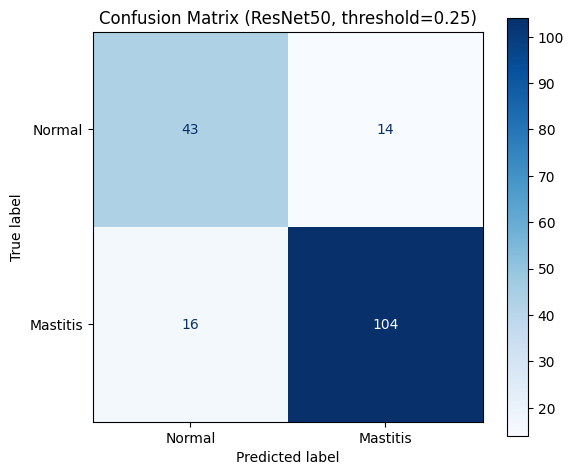

TN=43, FP=14, FN=16, TP=104
Accuracy: 0.8305
Precision: 0.8814
Recall (Sensitivity): 0.8667
Specificity: 0.7544


In [ ]:
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Mastitis'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix (ResNet50, threshold={FINAL_THRESHOLD})')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()

print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy: {(tp+tn)/(tp+tn+fp+fn):.4f}")
print(f"Precision: {tp/(tp+fp):.4f}")
print(f"Recall (Sensitivity): {tp/(tp+fn):.4f}")
print(f"Specificity: {tn/(tn+fp):.4f}")

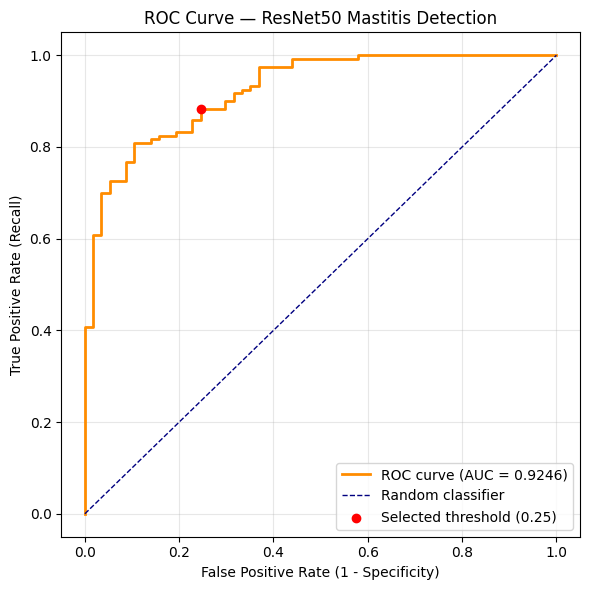

ROC-AUC: 0.9246


In [ ]:
fpr, tpr, roc_thresholds = roc_curve(y_true, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random classifier')

# Mark the selected threshold point
thresh_idx = np.argmin(np.abs(roc_thresholds - FINAL_THRESHOLD))
plt.scatter(fpr[thresh_idx], tpr[thresh_idx], color='red', zorder=5,
            label=f'Selected threshold ({FINAL_THRESHOLD})')

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — ResNet50 Mastitis Detection')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'roc_curve.png'), dpi=150)
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")

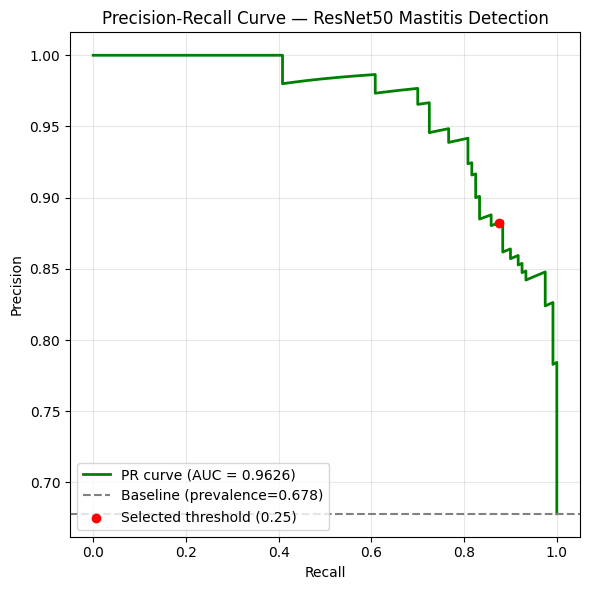

PR-AUC: 0.9626


In [ ]:
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_true, y_pred_proba)
pr_auc = auc(recall_vals, precision_vals)

plt.figure(figsize=(6, 6))
plt.plot(recall_vals, precision_vals, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')

baseline = np.sum(y_true) / len(y_true)
plt.axhline(y=baseline, color='gray', linestyle='--', label=f'Baseline (prevalence={baseline:.3f})')

# Mark the selected threshold point
pr_thresh_idx = np.argmin(np.abs(pr_thresholds - FINAL_THRESHOLD)) if len(pr_thresholds) > 0 else 0
plt.scatter(recall_vals[pr_thresh_idx], precision_vals[pr_thresh_idx], color='red', zorder=5,
            label=f'Selected threshold ({FINAL_THRESHOLD})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve — ResNet50 Mastitis Detection')
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'pr_curve.png'), dpi=150)
plt.show()

print(f"PR-AUC: {pr_auc:.4f}")

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

# Reload the CNN features and retrain the SVM (quick — already validated hyperparameters)
cnn_features_data = np.load(os.path.join(SAVE_DIR, 'cnn_features.npz'))
X_train_cnn = cnn_features_data['X_train']
y_train_cnn = cnn_features_data['y_train']
X_test_cnn = cnn_features_data['X_test']
y_test_cnn = cnn_features_data['y_test']

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

scaler_cnn = StandardScaler()
X_train_cnn_scaled = scaler_cnn.fit_transform(X_train_cnn)
X_test_cnn_scaled = scaler_cnn.transform(X_test_cnn)

svm_cnn = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, class_weight='balanced', random_state=42)
svm_cnn.fit(X_train_cnn_scaled, y_train_cnn)
svm_preds = svm_cnn.predict(X_test_cnn_scaled)

# IMPORTANT: confirm y_test_cnn matches y_true order (same test split, should be identical)
print(f"Labels match between CNN-feature test set and current test_ds: {np.array_equal(y_test_cnn, y_true)}")

# Build the McNemar 2x2 contingency table
# Compare ResNet50 end-to-end predictions (y_pred) vs SVM-on-CNN-features predictions (svm_preds)
resnet_correct = (y_pred == y_true)
svm_correct = (svm_preds == y_true)

both_correct = np.sum(resnet_correct & svm_correct)
resnet_only_correct = np.sum(resnet_correct & ~svm_correct)
svm_only_correct = np.sum(~resnet_correct & svm_correct)
both_wrong = np.sum(~resnet_correct & ~svm_correct)

contingency_table = [[both_correct, resnet_only_correct],
                      [svm_only_correct, both_wrong]]

print("\n=== McNemar's Test Contingency Table ===")
print(f"Both correct: {both_correct}")
print(f"ResNet50 correct, SVM wrong: {resnet_only_correct}")
print(f"SVM correct, ResNet50 wrong: {svm_only_correct}")
print(f"Both wrong: {both_wrong}")

result = mcnemar(contingency_table, exact=True if (resnet_only_correct + svm_only_correct) < 25 else False)
print(f"\nMcNemar's test statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")

alpha = 0.05
if result.pvalue < alpha:
    print(f"\n→ p < {alpha}: The difference between ResNet50 and SVM-on-CNN-features IS statistically significant.")
else:
    print(f"\n→ p >= {alpha}: The difference between ResNet50 and SVM-on-CNN-features is NOT statistically significant.")
    print("This means the two models perform comparably — either could be justified as 'best',")
    print("and the choice can be made on practical grounds (deployment simplicity, Grad-CAM support).")

Labels match between CNN-feature test set and current test_ds: True

=== McNemar's Test Contingency Table ===
Both correct: 141
ResNet50 correct, SVM wrong: 6
SVM correct, ResNet50 wrong: 8
Both wrong: 22

McNemar's test statistic: 6.0000
p-value: 0.7905

→ p >= 0.05: The difference between ResNet50 and SVM-on-CNN-features is NOT statistically significant.
This means the two models perform comparably — either could be justified as 'best',
and the choice can be made on practical grounds (deployment simplicity, Grad-CAM support).


In [ ]:
import time

# Reload all three architectures' Stage 1 checkpoints for fair comparison
model_paths = {
    'ResNet50': os.path.join(SAVE_DIR, 'resnet50_stage1_best.keras'),
}

# Check if EfficientNetB0/MobileNetV2 checkpoints exist from the original run
for name, fname in [('EfficientNetB0', 'efficientnetb0_stage1_best.keras'),
                      ('MobileNetV2', 'mobilenetv2_stage1_best.keras')]:
    fpath = os.path.join(SAVE_DIR, fname)
    if os.path.exists(fpath):
        model_paths[name] = fpath

print(f"Models available for benchmarking: {list(model_paths.keys())}")

benchmark_results = []

for name, path in model_paths.items():
    print(f"\nBenchmarking {name}...")
    model = tf.keras.models.load_model(path)

    file_size_mb = os.path.getsize(path) / (1024 * 1024)
    total_params = model.count_params()

    # Warm-up run (first inference includes graph tracing overhead, exclude from timing)
    dummy_input = np.random.uniform(0, 255, (1, 224, 224, 3)).astype(np.float32)
    _ = model.predict(dummy_input, verbose=0)

    # Timed runs — single image inference, averaged over 30 runs
    n_runs = 30
    times = []
    for _ in range(n_runs):
        start = time.time()
        _ = model.predict(dummy_input, verbose=0)
        times.append((time.time() - start) * 1000)  # ms

    avg_time_ms = np.mean(times)
    std_time_ms = np.std(times)

    benchmark_results.append({
        'model': name,
        'file_size_mb': round(file_size_mb, 2),
        'total_params': total_params,
        'avg_inference_ms': round(avg_time_ms, 2),
        'std_inference_ms': round(std_time_ms, 2)
    })

    print(f"  Size: {file_size_mb:.2f} MB | Params: {total_params:,} | "
          f"Inference: {avg_time_ms:.2f} ± {std_time_ms:.2f} ms")

    del model
    tf.keras.backend.clear_session()

df_benchmark = pd.DataFrame(benchmark_results)
print("\n=== Full Benchmark Table ===")
print(df_benchmark.to_string(index=False))

df_benchmark.to_csv(os.path.join(SAVE_DIR, 'inference_benchmark.csv'), index=False)
print(f"\nSaved to {SAVE_DIR}/inference_benchmark.csv")

Models available for benchmarking: ['ResNet50']

Benchmarking ResNet50...
  Size: 93.61 MB | Params: 23,850,113 | Inference: 79.08 ± 4.58 ms

=== Full Benchmark Table ===
   model  file_size_mb  total_params  avg_inference_ms  std_inference_ms
ResNet50         93.61      23850113             79.08              4.58

Saved to /content/drive/MyDrive/NewCattleSense/model1_artifacts/inference_benchmark.csv


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0, MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_model(backbone_name, input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)
    if backbone_name == 'efficientnetb0':
        x = tf.keras.applications.efficientnet.preprocess_input(inputs)
        base_model = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=x)
    elif backbone_name == 'mobilenetv2':
        x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return models.Model(inputs=inputs, outputs=outputs, name=f'{backbone_name}_mastitis')

train_ds = build_dataset(df_train_split, shuffle=True, augment=False)
val_ds = build_dataset(df_val_split, shuffle=False, augment=False)

def quick_train(backbone_name, epochs=15):
    model = build_model(backbone_name)
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
                           tf.keras.metrics.Precision(name='precision'),
                           tf.keras.metrics.Recall(name='recall')])
    callbacks = [
        EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
        ModelCheckpoint(os.path.join(SAVE_DIR, f'{backbone_name}_stage1_best.keras'),
                         monitor='val_auc', mode='max', save_best_only=True)
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                      class_weight=class_weight_dict, callbacks=callbacks, verbose=1)

print("=== Quick-training EfficientNetB0 ===")
eff_history = quick_train('efficientnetb0')

=== Quick-training EfficientNetB0 ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 262s 8s/step - accuracy: 0.7162 - auc: 0.8104 - loss: 0.5312 - precision: 0.8137 - recall: 0.6942 - val_accuracy: 0.8066 - val_auc: 0.8736 - val_loss: 0.4287 - val_precision: 0.8818 - val_recall: 0.8151 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 277ms/step - accuracy: 0.8120 - auc: 0.8981 - loss: 0.3927 - precision: 0.8945 - recall: 0.7847 - val_accuracy: 0.7514 - val_auc: 0.8982 - val_loss: 0.4949 - val_precision: 0.9512 - val_recall: 0.6555 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 229ms/step - accuracy: 0.8538 - auc: 0.9377 - loss: 0.3199 - precision: 0.9437 - recall: 0.8089 - val_accuracy: 0.7680 - val_auc: 0.9017 - val_loss: 0.4194 - val_precision: 0.9231 - val_recall: 0.7059 - learning_rate: 0.0010
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 228ms/step - accuracy: 0.8882 - auc: 0.9597 - loss: 0.2670 - precision: 0

In [ ]:
best_epoch_eff_quick = np.argmax(eff_history.history['val_auc']) + 1
print(f"Best epoch: {best_epoch_eff_quick}")
print(f"Best val_auc: {max(eff_history.history['val_auc']):.4f}")
print(f"Val accuracy at that epoch: {eff_history.history['val_accuracy'][best_epoch_eff_quick-1]:.4f}")

Best epoch: 14
Best val_auc: 0.9051
Val accuracy at that epoch: 0.7790


In [ ]:
print("=== Quick-training MobileNetV2 ===")
mob_history = quick_train('mobilenetv2')

=== Quick-training MobileNetV2 ===


/tmp/ipykernel_698/2730727621.py:13: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.7076 - auc: 0.7881 - loss: 0.5937 - precision: 0.7923 - recall: 0.7062 - val_accuracy: 0.7348 - val_auc: 0.9034 - val_loss: 0.5897 - val_precision: 0.9733 - val_recall: 0.6134 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 216ms/step - accuracy: 0.8157 - auc: 0.8981 - loss: 0.4008 - precision: 0.8864 - recall: 0.8008 - val_accuracy: 0.8177 - val_auc: 0.9222 - val_loss: 0.3938 - val_precision: 0.9574 - val_recall: 0.7563 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 207ms/step - accuracy: 0.8538 - auc: 0.9326 - loss: 0.3219 - precision: 0.9145 - recall: 0.8390 - val_accuracy: 0.7403 - val_auc: 0.9160 - val_loss: 0.6075 - val_precision: 0.9737 - val_recall: 0.6218 - learning_rate: 0.0010
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - accuracy: 0.8661 - auc: 0.9454 - loss: 0.2896 - precision: 0.9429 - recall: 0.8310 - val_accuracy: 0.

In [ ]:
best_epoch_mob_quick = np.argmax(mob_history.history['val_auc']) + 1
print(f"Best epoch: {best_epoch_mob_quick}")
print(f"Best val_auc: {max(mob_history.history['val_auc']):.4f}")
print(f"Val accuracy at that epoch: {mob_history.history['val_accuracy'][best_epoch_mob_quick-1]:.4f}")

Best epoch: 11
Best val_auc: 0.9393
Val accuracy at that epoch: 0.8619


In [ ]:
import time

model_paths = {
    'ResNet50': os.path.join(SAVE_DIR, 'resnet50_stage1_best.keras'),
    'EfficientNetB0': os.path.join(SAVE_DIR, 'efficientnetb0_stage1_best.keras'),
    'MobileNetV2': os.path.join(SAVE_DIR, 'mobilenetv2_stage1_best.keras'),
}

print(f"Models available for benchmarking: {list(model_paths.keys())}")

benchmark_results = []

for name, path in model_paths.items():
    print(f"\nBenchmarking {name}...")
    model = tf.keras.models.load_model(path)

    file_size_mb = os.path.getsize(path) / (1024 * 1024)
    total_params = model.count_params()

    dummy_input = np.random.uniform(0, 255, (1, 224, 224, 3)).astype(np.float32)
    _ = model.predict(dummy_input, verbose=0)  # warm-up

    n_runs = 30
    times = []
    for _ in range(n_runs):
        start = time.time()
        _ = model.predict(dummy_input, verbose=0)
        times.append((time.time() - start) * 1000)

    avg_time_ms = np.mean(times)
    std_time_ms = np.std(times)

    benchmark_results.append({
        'model': name,
        'file_size_mb': round(file_size_mb, 2),
        'total_params': total_params,
        'avg_inference_ms': round(avg_time_ms, 2),
        'std_inference_ms': round(std_time_ms, 2)
    })

    print(f"  Size: {file_size_mb:.2f} MB | Params: {total_params:,} | "
          f"Inference: {avg_time_ms:.2f} ± {std_time_ms:.2f} ms")

    del model
    tf.keras.backend.clear_session()

df_benchmark = pd.DataFrame(benchmark_results)
print("\n=== Full Benchmark Table ===")
print(df_benchmark.to_string(index=False))

df_benchmark.to_csv(os.path.join(SAVE_DIR, 'inference_benchmark.csv'), index=False)
print(f"\nSaved to inference_benchmark.csv")

Models available for benchmarking: ['ResNet50', 'EfficientNetB0', 'MobileNetV2']

Benchmarking ResNet50...
  Size: 93.61 MB | Params: 23,850,113 | Inference: 78.21 ± 3.59 ms

Benchmarking EfficientNetB0...
  Size: 18.13 MB | Params: 4,213,668 | Inference: 84.83 ± 18.57 ms

Benchmarking MobileNetV2...
  Size: 11.05 MB | Params: 2,422,081 | Inference: 92.81 ± 21.65 ms

=== Full Benchmark Table ===
         model  file_size_mb  total_params  avg_inference_ms  std_inference_ms
      ResNet50         93.61      23850113             78.21              3.59
EfficientNetB0         18.13       4213668             84.83             18.57
   MobileNetV2         11.05       2422081             92.81             21.65

Saved to inference_benchmark.csv


In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Reload classical (HOG+Color) features saved earlier
classical_data = np.load(os.path.join(SAVE_DIR, 'classical_features.npz'))
X_train_classical = classical_data['X_train']
y_train_classical = classical_data['y_train']
X_test_classical = classical_data['X_test']
y_test_classical = classical_data['y_test']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_classical)
X_test_scaled = scaler.transform(X_test_classical)

# 5-fold stratified CV, consistent with class imbalance handling used throughout
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

# --- Logistic Regression ---
print("=== GridSearchCV: Logistic Regression ===")
param_grid_lr = {'C': [0.01, 0.1, 1, 10]}
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
                        param_grid_lr, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train_classical)
print(f"Best params: {grid_lr.best_params_} | Best CV AUC: {grid_lr.best_score_:.4f}")
test_auc = grid_lr.score(X_test_scaled, y_test_classical)
cv_results.append({'model': 'Logistic Regression', 'best_params': str(grid_lr.best_params_),
                    'cv_auc_mean': grid_lr.best_score_, 'test_auc': test_auc})

# --- Decision Tree ---
print("\n=== GridSearchCV: Decision Tree ===")
param_grid_dt = {'max_depth': [5, 10, 15, None], 'min_samples_split': [5, 10, 20],
                  'min_samples_leaf': [2, 5, 10]}
grid_dt = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                        param_grid_dt, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_dt.fit(X_train_scaled, y_train_classical)
print(f"Best params: {grid_dt.best_params_} | Best CV AUC: {grid_dt.best_score_:.4f}")
test_auc = grid_dt.score(X_test_scaled, y_test_classical)
cv_results.append({'model': 'Decision Tree', 'best_params': str(grid_dt.best_params_),
                    'cv_auc_mean': grid_dt.best_score_, 'test_auc': test_auc})

# --- Random Forest ---
print("\n=== GridSearchCV: Random Forest ===")
param_grid_rf = {'n_estimators': [100, 200], 'max_depth': [10, 15, None],
                  'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}
grid_rf = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                        param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train_classical)
print(f"Best params: {grid_rf.best_params_} | Best CV AUC: {grid_rf.best_score_:.4f}")
test_auc = grid_rf.score(X_test_scaled, y_test_classical)
cv_results.append({'model': 'Random Forest', 'best_params': str(grid_rf.best_params_),
                    'cv_auc_mean': grid_rf.best_score_, 'test_auc': test_auc})

# --- SVM (RBF) ---
print("\n=== GridSearchCV: SVM (RBF) ===")
param_grid_svm = {'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1]}
grid_svm = GridSearchCV(SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
                         param_grid_svm, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train_classical)
print(f"Best params: {grid_svm.best_params_} | Best CV AUC: {grid_svm.best_score_:.4f}")
test_auc = grid_svm.score(X_test_scaled, y_test_classical)
cv_results.append({'model': 'SVM (RBF)', 'best_params': str(grid_svm.best_params_),
                    'cv_auc_mean': grid_svm.best_score_, 'test_auc': test_auc})

df_cv_results = pd.DataFrame(cv_results)
print("\n=== Cross-Validation Summary (5-Fold StratifiedKFold + GridSearchCV) ===")
print(df_cv_results.to_string(index=False))

df_cv_results.to_csv(os.path.join(SAVE_DIR, 'cross_validation_results.csv'), index=False)
print(f"\nSaved to cross_validation_results.csv")

=== GridSearchCV: Logistic Regression ===
Best params: {'C': 0.01} | Best CV AUC: 0.8692

=== GridSearchCV: Decision Tree ===
Best params: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 10} | Best CV AUC: 0.7023

=== GridSearchCV: Random Forest ===
Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200} | Best CV AUC: 0.8973

=== GridSearchCV: SVM (RBF) ===
Best params: {'C': 10, 'gamma': 'scale'} | Best CV AUC: 0.9181

=== Cross-Validation Summary (5-Fold StratifiedKFold + GridSearchCV) ===
              model                                                                           best_params  cv_auc_mean  test_auc
Logistic Regression                                                                           {'C': 0.01}     0.869209  0.758772
      Decision Tree                     {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 10}     0.702279  0.574050
      Random Forest {'max_depth': 10, 'min_samples_leaf': 

In [ ]:
print("=== Final Artifact Checklist ===")
for f in sorted(os.listdir(SAVE_DIR)):
    size = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1024
    print(f"  {f}: {size:.1f} KB")

=== Final Artifact Checklist ===
  class_names.json: 0.0 KB
  classical_features.npz: 56596.2 KB
  classical_ml_results.csv: 0.7 KB
  cnn_features.npz: 9382.0 KB
  confusion_matrix.png: 38.4 KB
  cross_validation_results.csv: 0.4 KB
  dataset_splits.csv: 285.0 KB
  efficientnetb0_stage1_best.keras: 18568.3 KB
  image_clusters.pkl: 73.1 KB
  inference_benchmark.csv: 0.2 KB
  mastitis_image_model.keras: 95854.4 KB
  metrics.json: 0.3 KB
  mobilenetv2_stage1_best.keras: 11319.1 KB
  pr_curve.png: 56.3 KB
  preprocessing_config.json: 0.1 KB
  resnet50_stage1_best.keras: 95860.8 KB
  roc_curve.png: 67.5 KB
  threshold.json: 0.1 KB


In [ ]:
try:
    print(f"resnet_history type: {type(resnet_history)}")
    print(f"Keys available: {list(resnet_history.history.keys())}")
    print("✓ resnet_history genuinely found in memory.")
except NameError:
    print("✗ resnet_history NOT in memory — runtime was restarted, need to retrain.")

✗ resnet_history NOT in memory — runtime was restarted, need to retrain.


=== Training FINAL ResNet50 run (single source of truth for paper) ===
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 43s 788ms/step - accuracy: 0.7211 - auc: 0.7997 - loss: 0.5986 - precision: 0.8027 - recall: 0.7203 - val_accuracy: 0.7624 - val_auc: 0.8697 - val_loss: 0.4187 - val_precision: 0.8393 - val_recall: 0.7899 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 300ms/step - accuracy: 0.8084 - auc: 0.9027 - loss: 0.3817 - precision: 0.8956 - recall: 0.7767 - val_accuracy: 0.7569 - val_auc: 0.8728 - val_loss: 0.4527 - val_precision: 0.9032 - val_recall: 0.7059 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 378ms/step - accuracy: 0.8378 - auc: 0.9161 - loss: 0.3599 - precision: 0.9011 - recall: 0.8249 - val_accuracy: 0.7680 - val_auc: 0.8925 - val_loss: 0.4980 - val_precision: 0.9753 - val_recall: 0.6639 - learning_rate: 0.0010
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 299ms/step - accuracy: 0.8452 - auc: 0.9292 - loss: 0.3282 - precision: 0.9264 - recall:

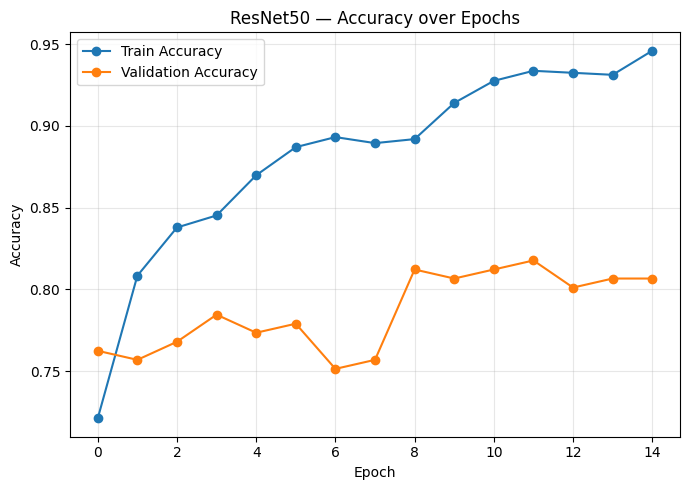

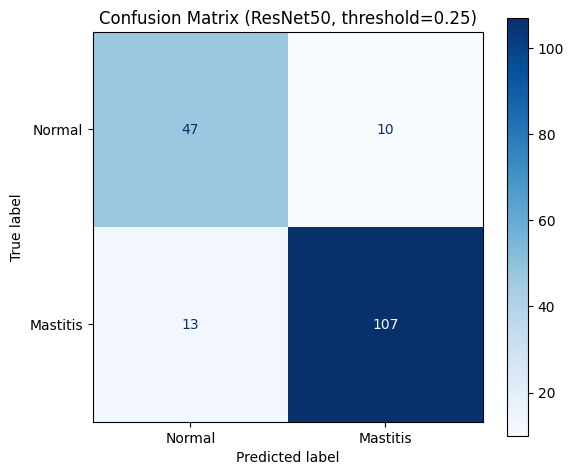

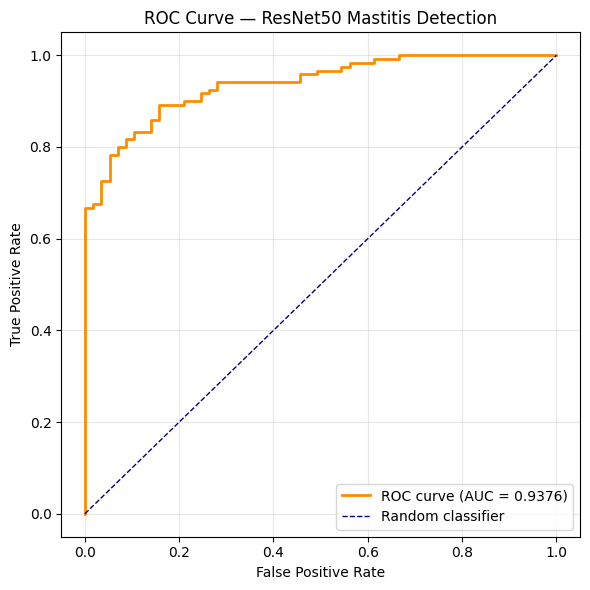


=== ALL SAVED — single consistent source for paper ===
{
  "model": "ResNet50 (frozen backbone, Stage 1)",
  "best_epoch": 12,
  "train_accuracy": 93.37,
  "validation_accuracy": 81.77,
  "validation_auc": 0.9102,
  "test_accuracy": 87.01,
  "test_precision": 91.45,
  "test_recall": 89.17,
  "test_roc_auc": 0.9376,
  "confusion_matrix": {
    "TN": 47,
    "FP": 10,
    "FN": 13,
    "TP": 107
  }
}


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, roc_curve, auc, ConfusionMatrixDisplay

print("=== Training FINAL ResNet50 run (single source of truth for paper) ===")
resnet_model_final = build_model('resnet50')
resnet_history_final = compile_and_train_stage1(resnet_model_final, 'resnet50_final', train_ds, val_ds)

# Save history immediately
best_epoch_final = int(np.argmax(resnet_history_final.history['val_auc'])) + 1
history_serializable = {k: [float(v) for v in vals] for k, vals in resnet_history_final.history.items()}
with open(os.path.join(SAVE_DIR, 'resnet50_final_history.json'), 'w') as f:
    json.dump(history_serializable, f, indent=2)

print(f"\nBest epoch: {best_epoch_final}")
print(f"Train Accuracy @ best epoch: {resnet_history_final.history['accuracy'][best_epoch_final-1]*100:.2f}%")
print(f"Validation Accuracy @ best epoch: {resnet_history_final.history['val_accuracy'][best_epoch_final-1]*100:.2f}%")
print(f"Validation AUC @ best epoch: {resnet_history_final.history['val_auc'][best_epoch_final-1]:.4f}")

# Load the BEST checkpoint saved during this run (not the in-memory final-epoch weights)
final_model_for_eval = tf.keras.models.load_model(os.path.join(SAVE_DIR, 'resnet50_final_stage1_best.keras'))

# Evaluate on test set — SAME run
df_test_final = pd.read_csv(os.path.join(SAVE_DIR, 'dataset_splits.csv'))
df_test_final = df_test_final[df_test_final['split'] == 'test'].reset_index(drop=True)
test_ds_final = build_dataset(df_test_final, shuffle=False, augment=False)

y_true_final, y_proba_final = [], []
for imgs, labels in test_ds_final:
    preds = final_model_for_eval.predict(imgs, verbose=0)
    y_proba_final.extend(preds.flatten())
    y_true_final.extend(labels.numpy())
y_true_final = np.array(y_true_final)
y_proba_final = np.array(y_proba_final)
y_pred_final = (y_proba_final >= 0.25).astype(int)

cm_final = confusion_matrix(y_true_final, y_pred_final)
tn, fp, fn, tp = cm_final.ravel()
test_acc = accuracy_score(y_true_final, y_pred_final)
test_prec = precision_score(y_true_final, y_pred_final)
test_rec = recall_score(y_true_final, y_pred_final)
test_auc = roc_auc_score(y_true_final, y_proba_final)

print(f"\n=== TEST SET (same run) ===")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Precision: {test_prec*100:.2f}%")
print(f"Recall: {test_rec*100:.2f}%")
print(f"ROC-AUC: {test_auc:.4f}")

# --- Generate all 3 figures from THIS SAME run ---

# Fig 1: Accuracy graph
plt.figure(figsize=(7, 5))
plt.plot(resnet_history_final.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(resnet_history_final.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('ResNet50 — Accuracy over Epochs')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'FINAL_resnet50_accuracy.png'), dpi=150)
plt.show()

# Fig 2: Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Normal', 'Mastitis'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix (ResNet50, threshold=0.25)')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'FINAL_confusion_matrix.png'), dpi=150)
plt.show()

# Fig 3: ROC Curve
fpr, tpr, _ = roc_curve(y_true_final, y_proba_final)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve — ResNet50 Mastitis Detection')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'FINAL_roc_curve.png'), dpi=150)
plt.show()

# Save the final, single-source-of-truth summary
final_summary = {
    "model": "ResNet50 (frozen backbone, Stage 1)",
    "best_epoch": best_epoch_final,
    "train_accuracy": round(resnet_history_final.history['accuracy'][best_epoch_final-1]*100, 2),
    "validation_accuracy": round(resnet_history_final.history['val_accuracy'][best_epoch_final-1]*100, 2),
    "validation_auc": round(resnet_history_final.history['val_auc'][best_epoch_final-1], 4),
    "test_accuracy": round(test_acc*100, 2),
    "test_precision": round(test_prec*100, 2),
    "test_recall": round(test_rec*100, 2),
    "test_roc_auc": round(test_auc, 4),
    "confusion_matrix": {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
}
with open(os.path.join(SAVE_DIR, 'FINAL_paper_numbers.json'), 'w') as f:
    json.dump(final_summary, f, indent=2)

print("\n=== ALL SAVED — single consistent source for paper ===")
print(json.dumps(final_summary, indent=2))

In [ ]:
import shutil
shutil.copy(
    os.path.join(SAVE_DIR, 'resnet50_final_stage1_best.keras'),
    os.path.join(SAVE_DIR, 'mastitis_image_model_FINAL.keras')
)
print("Ready for download: mastitis_image_model_FINAL.keras")

Ready for download: mastitis_image_model_FINAL.keras
